# 📦 Amazon Marketplace Profit Analytics
**Business question:** Where does our profit come from, where do we lose money, and can we predict a loss-making order *before* it ships?

**Approach:** order-level P&L analysis → discount & returns economics → ML loss-risk model (chronological hold-out) → what-if pricing simulation.

> Data is **synthetic** (simulated with realistic retail economics). The method transfers to any real order export with the same columns.

In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd
from IPython.display import Image, Markdown, display
from src.config import FIG, REPORTS, ROOT
from src.generate_data import load_or_create
from src import analysis as an

df = load_or_create()
metrics = json.loads((REPORTS / 'metrics.json').read_text())
show = lambda name, w=900: display(Image(filename=str(FIG / name), width=w))
df.head()

,order_id,order_date,customer_id,customer_segment,customer_return_rate,category,region,fulfilment,shipping_mode,quantity,...,fulfilment_cost,marketing_cost,returned,net_revenue,cogs,cogs_recognised,return_shipping_cost,profit,profit_margin_pct,is_loss_making
0,AMZ-0000000,2024-01-01,CUST000121,Standard,0.127,Books,North,FBA,Standard,1,...,36.80,7.72,0,218.18,141.12,141.12,0.0,7.30,3.35,0
1,AMZ-0000001,2024-01-01,CUST012751,Prime,0.021,Beauty & Personal Care,South,Merchant,Expedited,4,...,45.51,45.13,0,1567.28,975.80,975.80,0.0,404.79,25.83,0
2,AMZ-0000002,2024-01-01,CUST006497,Prime,0.077,Toys & Games,Central,Merchant,Expedited,1,...,30.81,21.73,0,587.50,323.44,323.44,0.0,105.32,17.93,0
3,AMZ-0000003,2024-01-01,CUST006123,Prime,0.028,Electronics,South,FBA,Expedited,2,...,624.68,794.73,0,26940.00,23387.06,23387.06,0.0,1959.44,7.27,0
4,AMZ-0000004,2024-01-01,CUST002037,Prime,0.019,Sports & Fitness,West,FBA,Expedited,1,...,80.92,187.42,0,2223.58,1380.71,1380.71,0.0,473.81,21.31,0


## 1. Data quality & scope

In [2]:
print(f"{len(df):,} orders | {df.order_date.min():%d %b %Y} to {df.order_date.max():%d %b %Y} | {df.customer_id.nunique():,} customers")
print('Missing values:', int(df.isna().sum().sum()), '| duplicate order IDs:', int(df.order_id.duplicated().sum()))
df.describe().T[['mean','50%','max']].round(1).head(12)

40,000 orders | 01 Jan 2024 to 31 Dec 2025 | 14,770 customers
Missing values: 0 | duplicate order IDs: 0


,mean,50%,max
order_date,2025-02-07 08:57:30.960000,2025-02-09 00:00:00,2025-12-31 00:00:00
customer_return_rate,0.070317,0.054,0.543
quantity,1.4293,1.0,4.0
list_price,4570.562275,1686.0,100870.0
discount_pct,14.875953,13.7,60.0
selling_price,3857.591097,1400.435,83722.1
unit_cost,3180.858938,912.325,75028.47
gross_sales,5496.581015,1824.69,300397.68
shipping_cost,127.723742,86.31,2334.26
fulfilment_cost,134.723719,64.185,6640.75


## 2. Headline KPIs

In [3]:
k = an.kpis(df)
pd.Series(k).to_frame('value')

,value
orders,40000.00
gross_sales_m,219.86
net_revenue_m,204.87
profit_m,14.90
margin_pct,7.27
loss_making_pct,18.90
return_rate_pct,6.80
avg_profit_per_order,372.50


## 3. Where does each rupee of sales go?

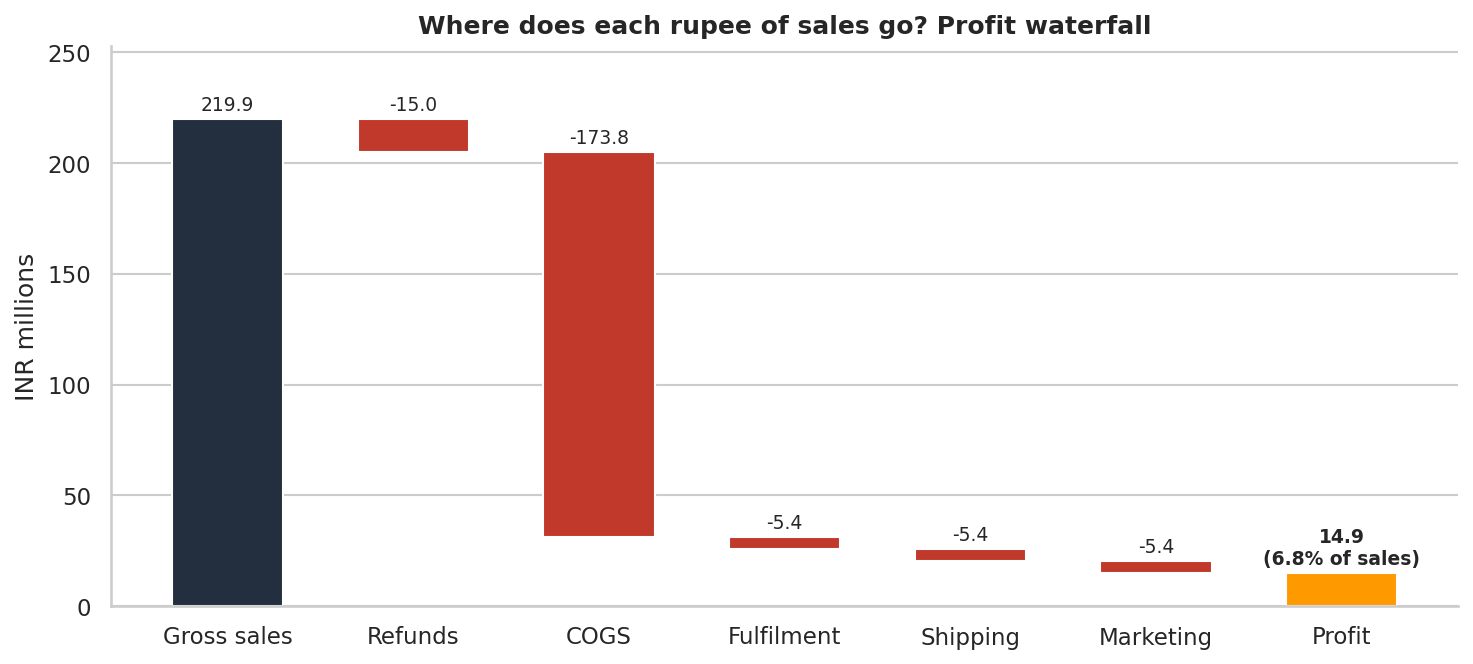

In [4]:
show('02_profit_waterfall.png')

COGS dominates. The controllable leaks are **refunds**, **discounting** and **logistics**.

## 4. Seasonality - revenue up, margin down

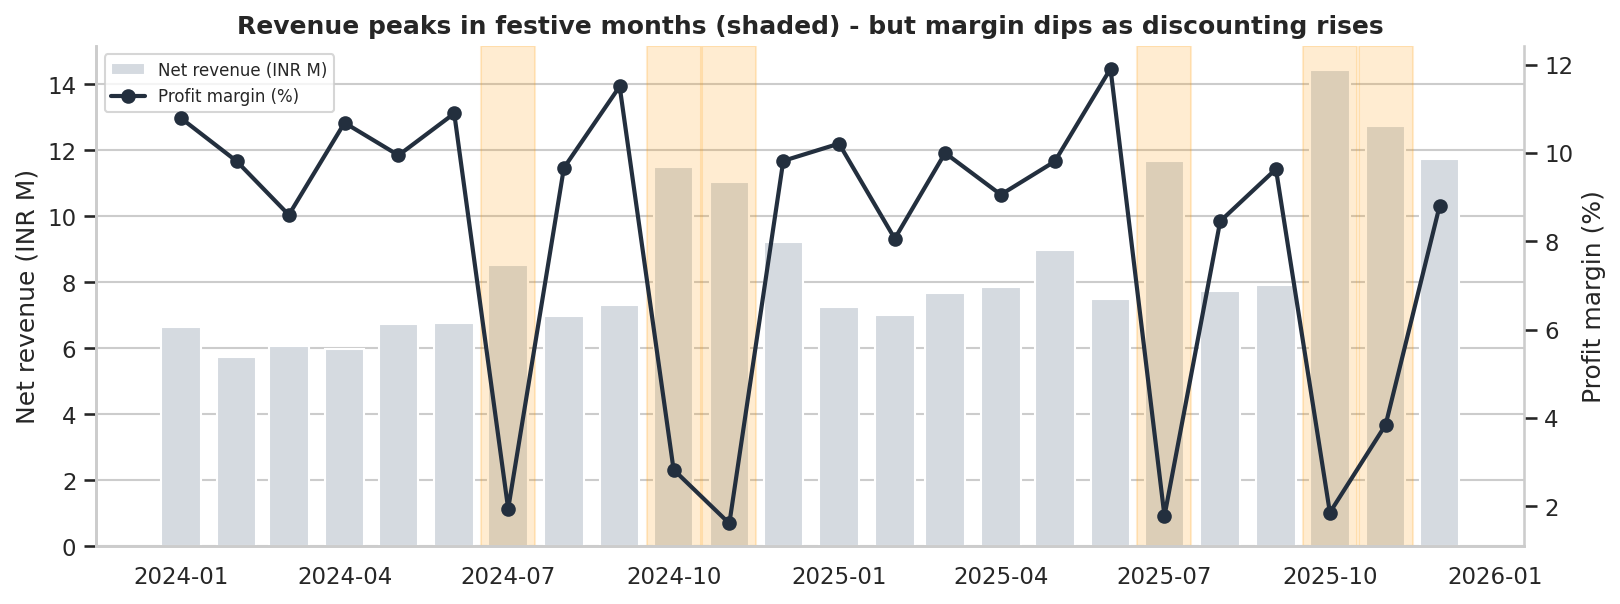

Festive months run **18.8%** average discount vs **12.7%** otherwise, cutting margin from **9.83%** to **2.34%**.

In [5]:
show('01_monthly_trend.png', 1000)
a = metrics['analysis']
Markdown(f"Festive months run **{a['festive_avg_discount']}%** average discount vs **{a['regular_avg_discount']}%** otherwise, "
         f"cutting margin from **{a['regular_margin_pct']}%** to **{a['festive_margin_pct']}%**.")

## 5. Category profitability

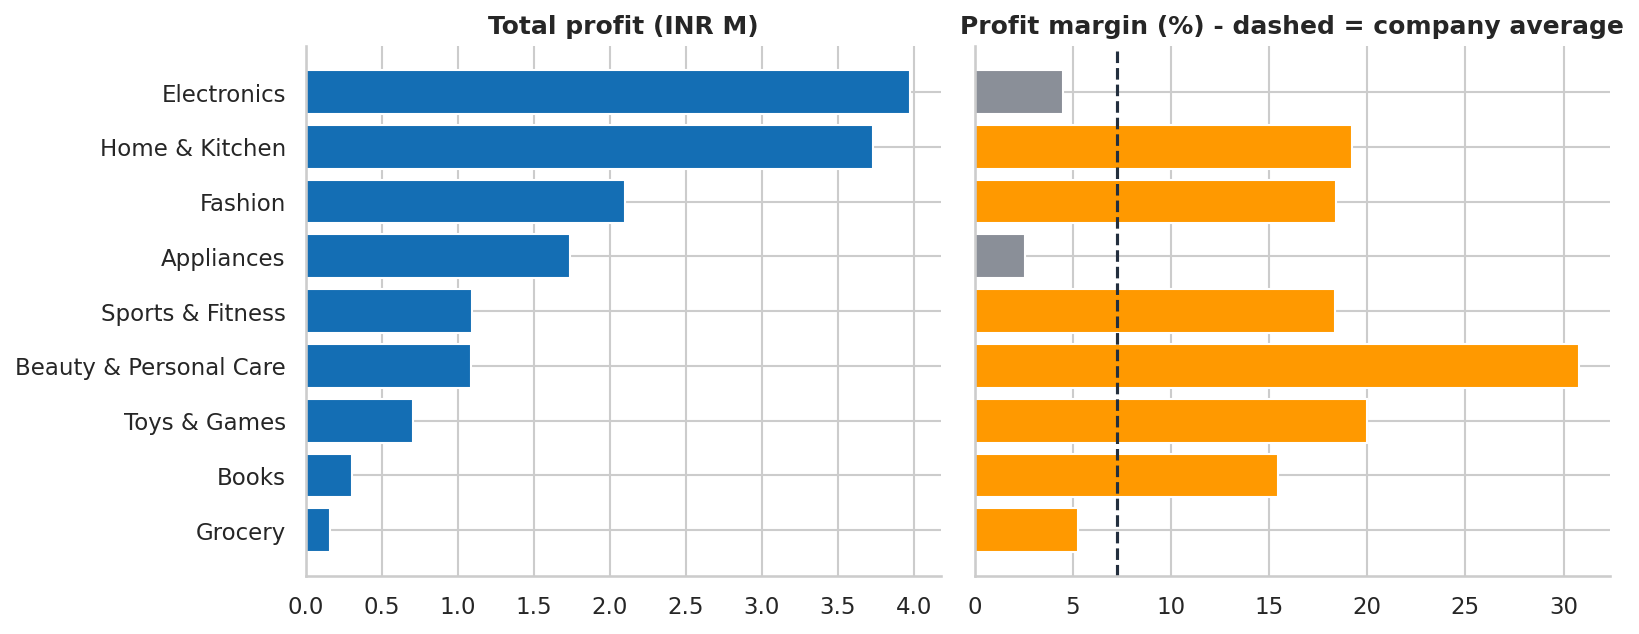

,orders,profit,margin_pct,loss_pct,return_pct,avg_discount
category,,,,,,
Electronics,8009,3976194.7,4.5,27.6,7.3,16.1
Home & Kitchen,6351,3733782.4,19.2,11.3,6.5,13.2
Fashion,7234,2102433.2,18.4,14.5,9.5,21.1
Appliances,2453,1735629.0,2.6,32.8,6.4,15.3
Sports & Fitness,2435,1095969.1,18.4,11.6,6.7,13.0
Beauty & Personal Care,3969,1087842.8,30.8,7.4,5.8,15.1
Toys & Games,2447,705831.7,20.0,10.9,5.7,13.1
Books,3173,304919.8,15.5,18.7,5.1,10.1
Grocery,3929,157574.2,5.3,34.5,4.4,9.3


In [6]:
show('03_category_profitability.png', 1000)
an.by_dim(df, 'category')[['orders','profit','margin_pct','loss_pct','return_pct','avg_discount']].round(1)

## 6. Discount economics

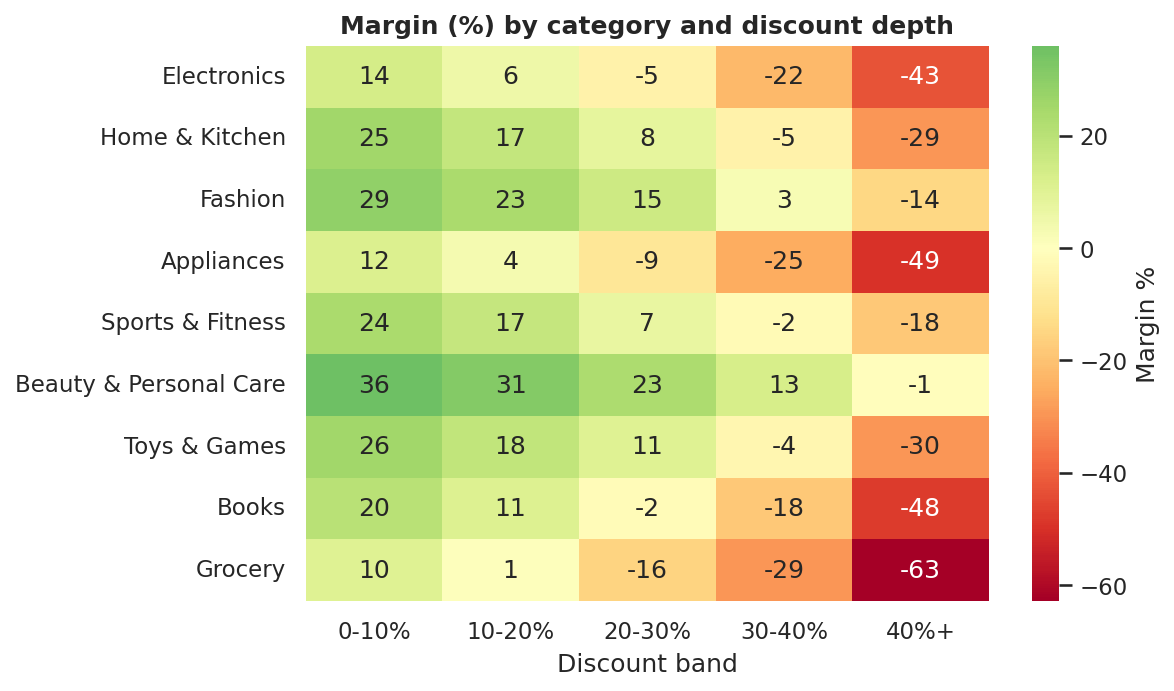

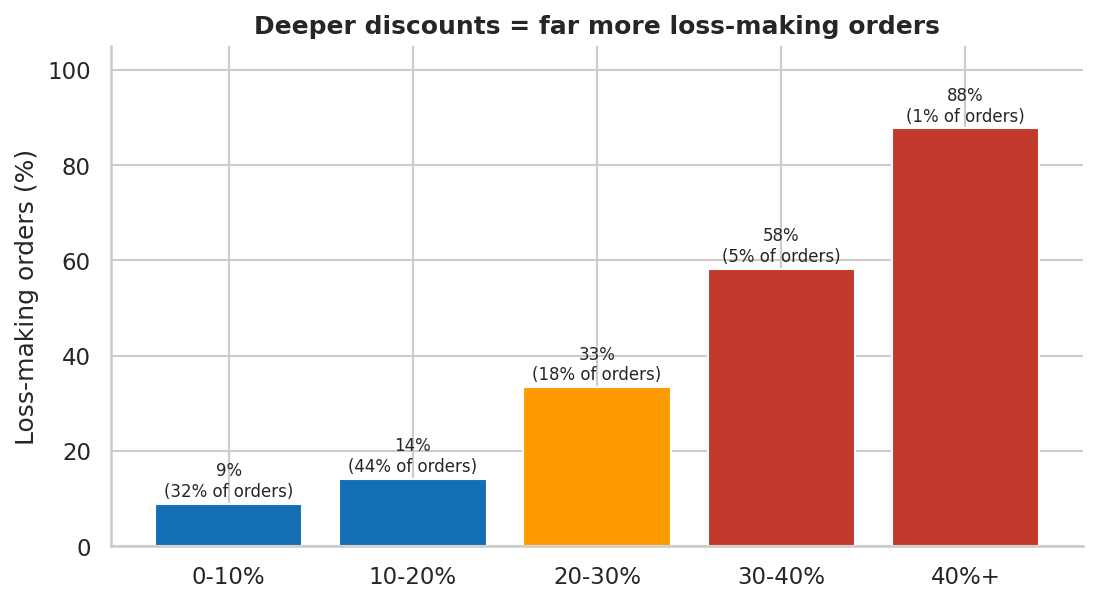

In [7]:
show('04_discount_margin_heatmap.png', 700); show('05_loss_rate_by_discount.png', 650)

Beyond ~20-30% discount, most categories flip from profit to loss. Electronics, Appliances, Books and Grocery turn negative first because of thin gross margins.

## 7. Operations & returns

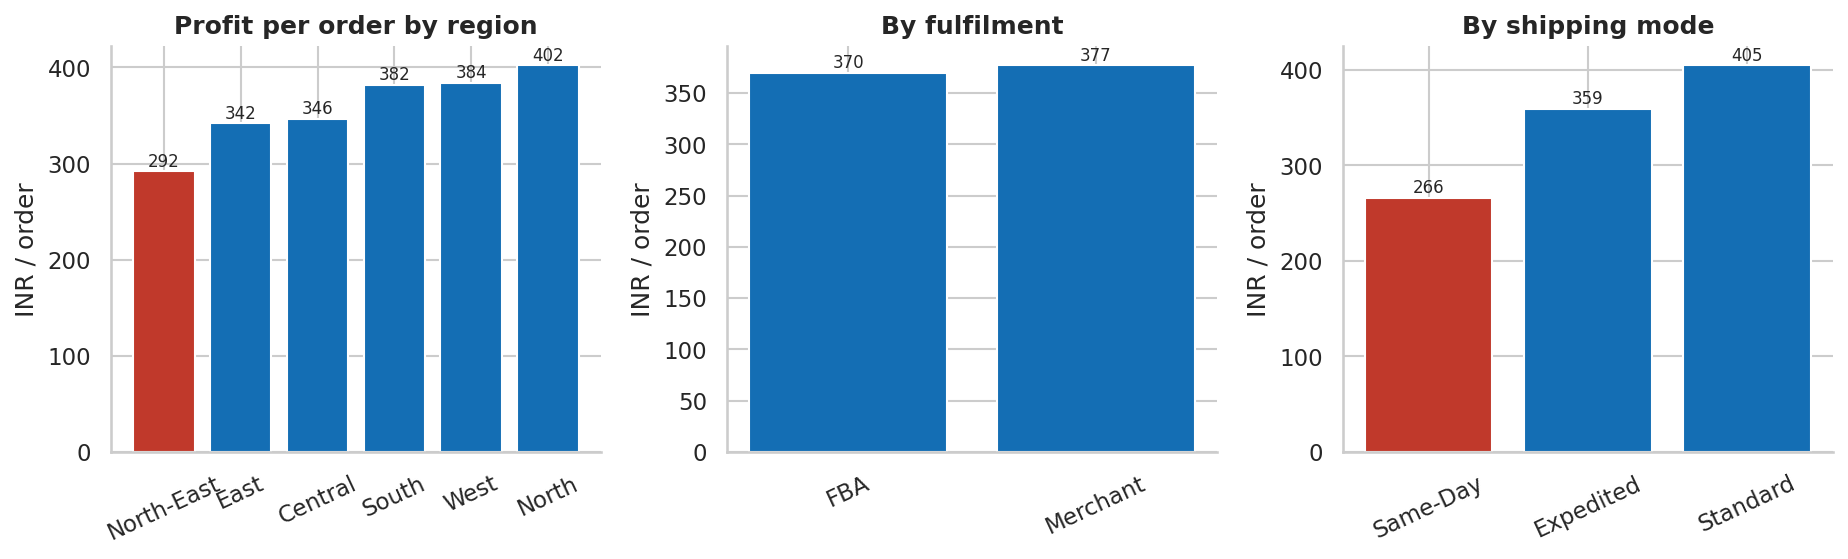

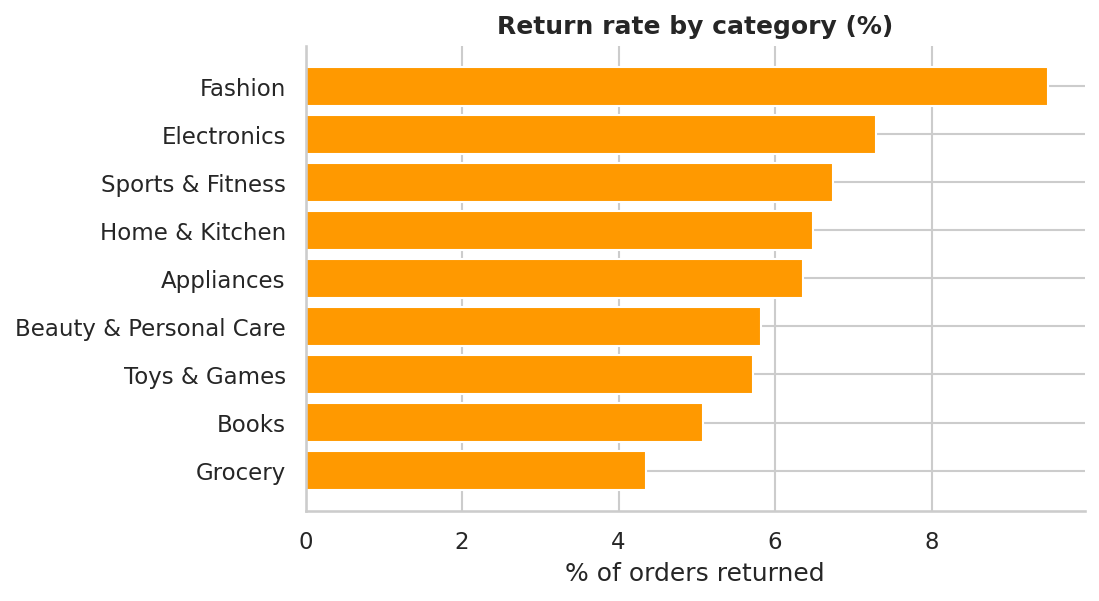

In [8]:
show('06_operations.png', 1000); show('07_returns.png', 650)

## 8. What-if: capping discounts

In [9]:
pd.DataFrame(a['scenarios'])[['cap','pct_orders_affected','baseline_profit_m','new_profit_m','uplift_m','uplift_pct']]

,cap,pct_orders_affected,baseline_profit_m,new_profit_m,uplift_m,uplift_pct
0,20,24.1,14.9,18.80,3.90,26.2
1,25,12.0,14.9,16.91,2.01,13.5
2,30,5.8,14.9,15.90,1.00,6.7
3,35,2.7,14.9,15.37,0.47,3.2


*Assumes 15% of affected orders are lost after repricing. Real price elasticity should be measured with an A/B test.*

## 9. Machine learning: predict loss-making orders at order time
- **Target:** `is_loss_making`  |  **Features:** only information known before shipping (price, discount, costs, category, region, customer return history...)
- **Leakage control:** outcome columns (`returned`, `net_revenue`, `profit`, ...) are excluded and enforced by an assertion + unit test
- **Validation:** chronological split (train on the past, test on the most recent 20% of orders) + 5-fold CV for model selection

In [10]:
m = metrics['model']
pd.DataFrame(m['classification']).T

,cv_accuracy,cv_auc,test_accuracy,test_precision,test_recall,test_f1,test_auc
Logistic Regression,0.9177,0.8433,0.9101,0.9382,0.6520,0.7693,0.8764
Random Forest,0.9411,0.8612,0.9421,1.0000,0.7482,0.8560,0.8893
Gradient Boosting,0.9402,0.8714,0.9410,0.9949,0.7471,0.8534,0.9025


In [11]:
b = m['classification'][m['best_classifier']]
Markdown(f"**{m['best_classifier']}** - test accuracy **{b['test_accuracy']:.1%}** (majority-class baseline {m['baseline_accuracy']:.1%}), "
         f"precision {b['test_precision']:.1%}, recall {b['test_recall']:.1%}, ROC-AUC {b['test_auc']:.3f}.")

**Gradient Boosting** - test accuracy **94.1%** (majority-class baseline 77.0%), precision 99.5%, recall 74.7%, ROC-AUC 0.902.

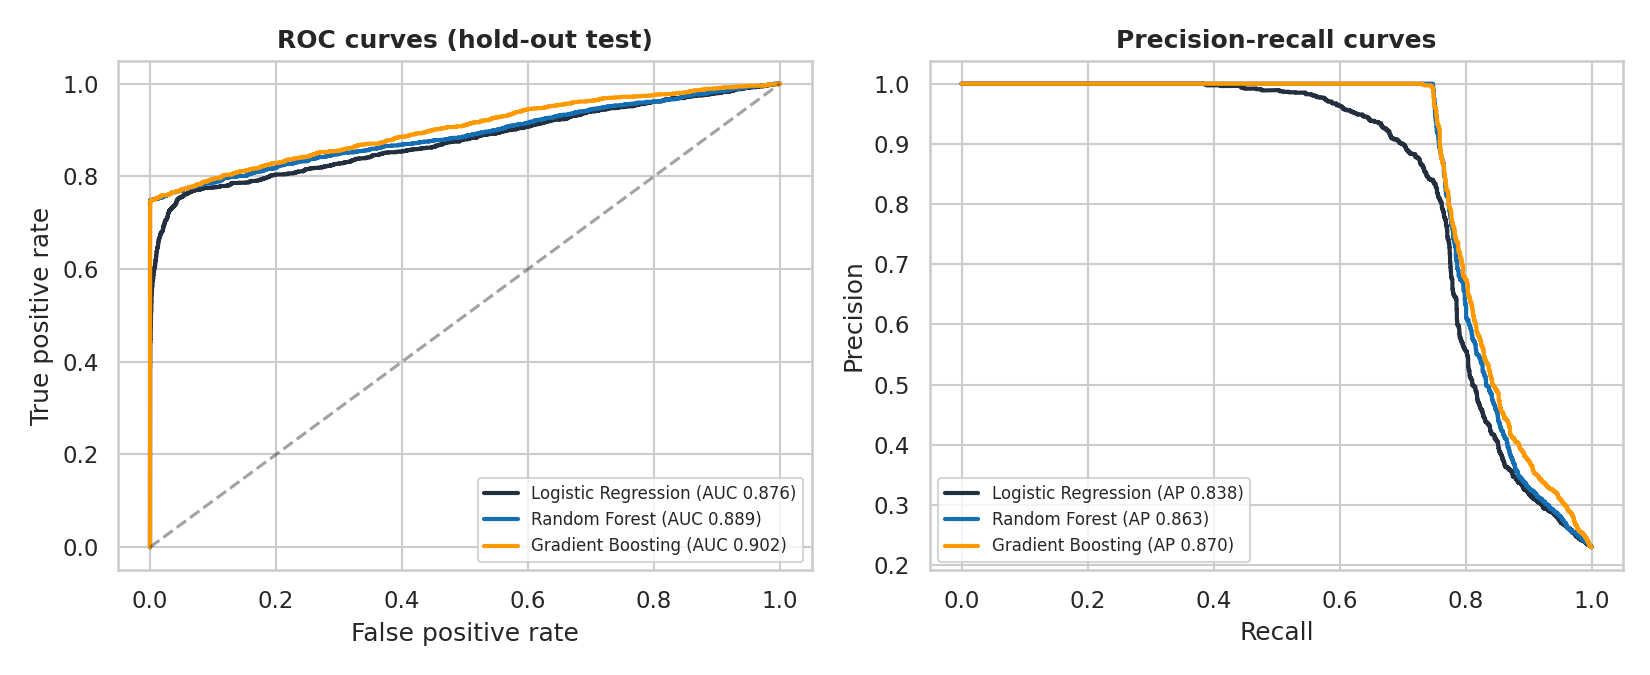

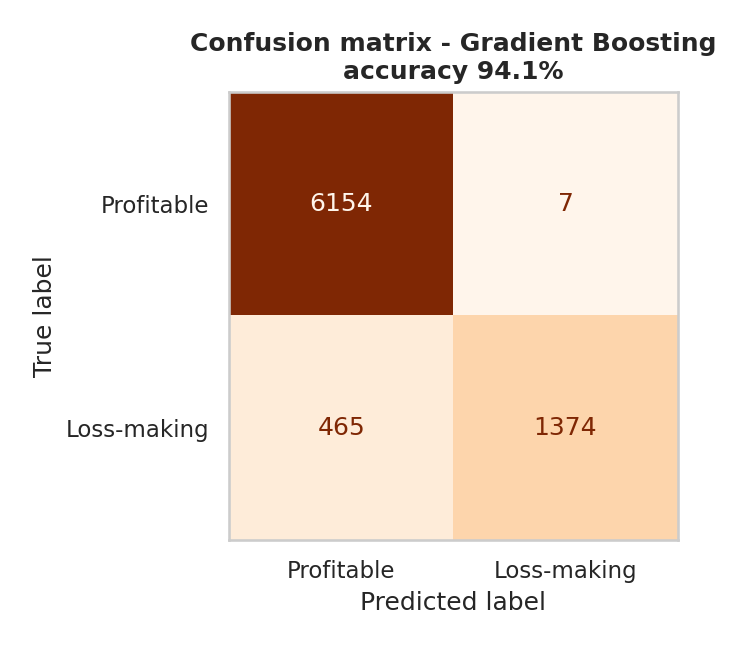

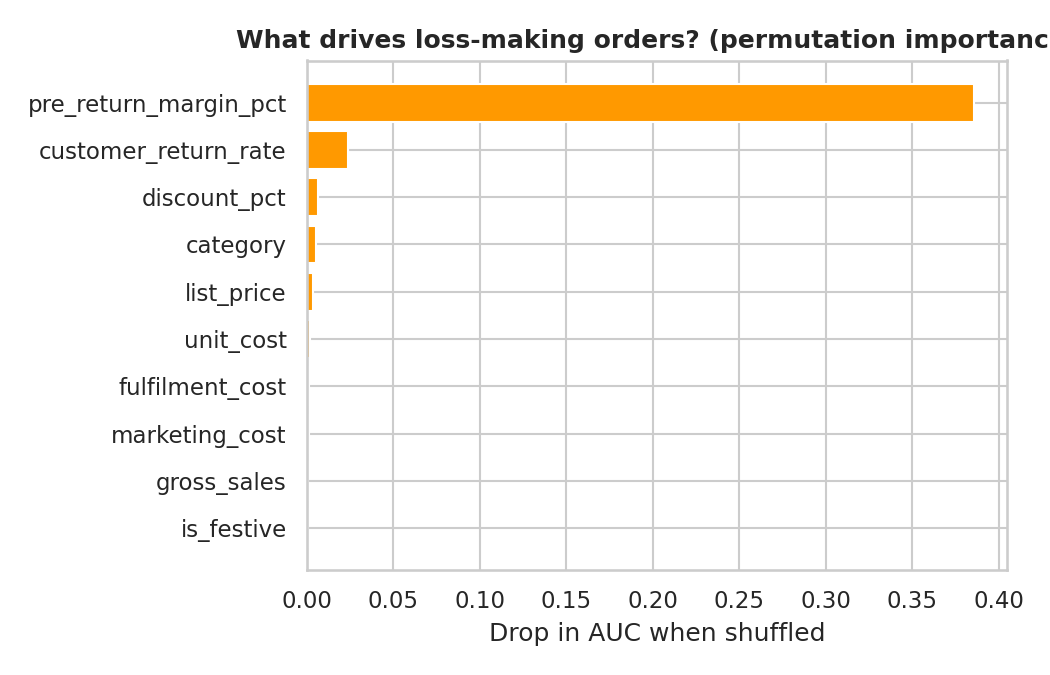

In [12]:
show('08_roc_pr_curves.png', 950); show('09_confusion_matrix.png', 420); show('10_feature_importance.png', 650)

### Why are some losses missed?

In [13]:
Markdown(f"Of the true loss-making orders the model missed, **{m['missed_losses']['pct_caused_by_returns']}%** were caused by customer returns - "
         "which cannot be known when the order is placed. The remaining error is therefore irreducible, not a modelling flaw.")

Of the true loss-making orders the model missed, **99.4%** were caused by customer returns - which cannot be known when the order is placed. The remaining error is therefore irreducible, not a modelling flaw.

## 10. Executive summary

In [14]:
Markdown((REPORTS / 'executive_summary.md').read_text())

# Executive Summary - Marketplace Profitability

**Headline:** 40,000 orders generated INR 204.87M net revenue and INR 14.9M profit
(**7.27% margin**). 18.9% of orders lose money, and 77.3% of those
involve either a discount above 20% or a customer return.

## What drives profit
1. **Category mix.** Electronics contributes the most profit (INR 4.0M); Beauty & Personal Care earns the best margin
   (30.8%) while Appliances earns the thinnest (2.6%).
2. **Discount depth.** Loss-making rate climbs from 9.0% at 0-10% discount to
   87.7% above 40%. Orders discounted over 20% *destroy* INR
   2.8M of profit.
3. **Seasonality.** Festive months (Jul, Oct, Nov) average 18.8% discount vs 12.7% normally, cutting
   margin from 9.83% to **2.34%** despite record revenue.

## Where we lose money
- **Returns:** 6.8% of orders are returned, costing INR 6.38M; Fashion is worst at 9.5%.
- **Pricing leakage:** INR 3.01M lost on orders that were *kept* by customers but sold below cost-to-serve.
- **Logistics:** Same-day orders earn INR 266 per order vs INR 405 for standard;
  North-East earns INR 292 vs INR 402 in the North.

## Recommendations
1. **Cap discounts at 25%** (affects 12.0% of orders). Even assuming 15% of affected orders are lost,
   profit rises by **INR 2.01M (+13.5%)**.
2. **Use the loss-risk model at pricing time** to block or reprice orders flagged as likely loss-makers.
3. **Attack returns** in Fashion (size guidance, quality checks) and add a return-risk surcharge for repeat returners.

## Model performance
The best model (Gradient Boosting) predicts whether an order will lose money with **94.1% accuracy**
on a chronological hold-out (2025-09-24 to 2025-12-31), versus a 77.0% majority-class baseline;
precision 99.5%, recall 74.7%, AUC 0.902.
Of 1839 true loss-making orders it caught 1374; 99.4% of the misses were
caused by customer returns, which cannot be known at order time.

## Limitations
Data is simulated, so absolute figures illustrate the method, not Amazon's real economics. Discount scenarios
assume 15% volume loss on repriced orders; real elasticity should be measured with an A/B test.
